Batch Gradient Descent
Weight: 19.670775089888583
Bias: 65.99999988892412
Final Loss: 2.0606060606060788

Stochastic Gradient Descent
Weight: 19.672676246532664
Bias: 65.99587185512867
Final Loss: 2.0606267164568512

Mini-Batch Gradient Descent
Weight: 19.688289046078317
Bias: 65.99457397956807
Final Loss: 2.0609422398056028


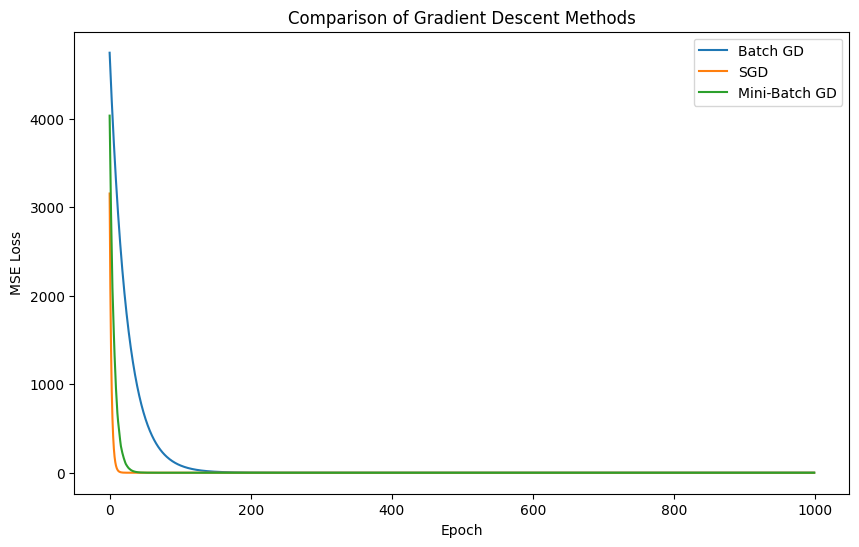

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


data = {
    "Hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Score": [35, 40, 50, 55, 65, 70, 75, 85, 90, 95]
}

df = pd.DataFrame(data)

X = df["Hours"].values
y = df["Score"].values


X = (X - X.mean()) / X.std()



def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)




def batch_gradient_descent(X, y, learning_rate=0.01, epochs=1000):

    w = 0
    b = 0

    losses = []

    n = len(X)

    for epoch in range(epochs):


        y_pred = w * X + b


        dw = (-2 / n) * np.sum(X * (y - y_pred))
        db = (-2 / n) * np.sum(y - y_pred)


        w = w - learning_rate * dw
        b = b - learning_rate * db


        losses.append(mse(y, y_pred))

    return w, b, losses




def stochastic_gradient_descent(X, y, learning_rate=0.01, epochs=1000):

    w = 0
    b = 0

    losses = []

    n = len(X)

    for epoch in range(epochs):


        indices = np.random.permutation(n)

        for i in indices:

            xi = X[i]
            yi = y[i]


            y_pred = w * xi + b


            dw = -2 * xi * (yi - y_pred)
            db = -2 * (yi - y_pred)


            w = w - learning_rate * dw
            b = b - learning_rate * db


        y_pred = w * X + b
        losses.append(mse(y, y_pred))

    return w, b, losses




def mini_batch_gradient_descent(
        X, y,
        learning_rate=0.01,
        epochs=1000,
        batch_size=3):

    w = 0
    b = 0

    losses = []

    n = len(X)

    for epoch in range(epochs):


        indices = np.random.permutation(n)

        X_shuffled = X[indices]
        y_shuffled = y[indices]


        for start in range(0, n, batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]


            y_pred = w * X_batch + b

            batch_n = len(X_batch)


            dw = (-2 / batch_n) * np.sum(
                X_batch * (y_batch - y_pred)
            )

            db = (-2 / batch_n) * np.sum(
                y_batch - y_pred
            )


            w = w - learning_rate * dw
            b = b - learning_rate * db


        y_pred = w * X + b
        losses.append(mse(y, y_pred))

    return w, b, losses




w_batch, b_batch, loss_batch = batch_gradient_descent(
    X, y
)

w_sgd, b_sgd, loss_sgd = stochastic_gradient_descent(
    X, y
)

w_mini, b_mini, loss_mini = mini_batch_gradient_descent(
    X, y
)




print("Batch Gradient Descent")
print("Weight:", w_batch)
print("Bias:", b_batch)
print("Final Loss:", loss_batch[-1])

print("\nStochastic Gradient Descent")
print("Weight:", w_sgd)
print("Bias:", b_sgd)
print("Final Loss:", loss_sgd[-1])

print("\nMini-Batch Gradient Descent")
print("Weight:", w_mini)
print("Bias:", b_mini)
print("Final Loss:", loss_mini[-1])




plt.figure(figsize=(10, 6))

plt.plot(loss_batch, label="Batch GD")
plt.plot(loss_sgd, label="SGD")
plt.plot(loss_mini, label="Mini-Batch GD")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Comparison of Gradient Descent Methods")
plt.legend()
plt.show()


Dataset: Diabetes
Batch GD Theta: [[-1.40228452e-16]
 [ 5.82978039e-01]]
Batch GD Final Cost: 0.32804414760970096
SGD Theta: [[-0.04062355]
 [ 0.6086783 ]]
SGD Final Cost: 0.32911030195690494
Mini-Batch GD Theta: [[-0.01491003]
 [ 0.58743385]]
Mini-Batch GD Final Cost: 0.3281497582112662


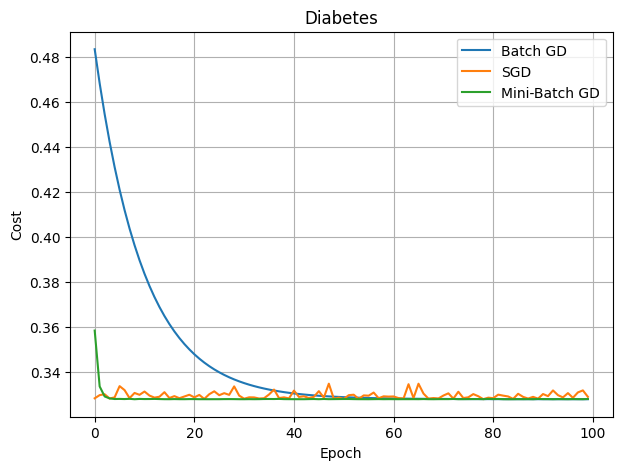


Dataset: Linnerud
Batch GD Theta: [[ 3.05311332e-16]
 [-3.87386458e-01]]
Batch GD Final Cost: 0.42407209083069136
SGD Theta: [[ 0.00597045]
 [-0.40085623]]
SGD Final Cost: 0.4241495540124259
Mini-Batch GD Theta: [[ 0.00546965]
 [-0.38345348]]
Mini-Batch GD Final Cost: 0.4241038576979609


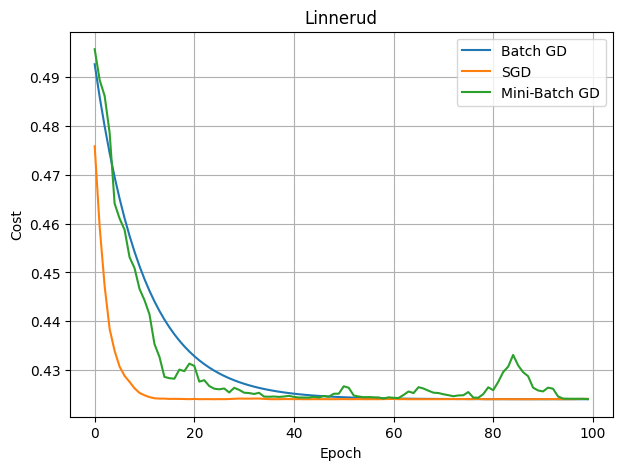


Dataset: Student Performance
Batch GD Theta: [[3.58602037e-16]
 [9.41508995e-01]]
Batch GD Final Cost: 0.05150096024624074
SGD Theta: [[-0.00353072]
 [ 0.94985312]]
SGD Final Cost: 0.0514952163409413
Mini-Batch GD Theta: [[-0.00846403]
 [ 0.94342943]]
Mini-Batch GD Final Cost: 0.05152785546035847


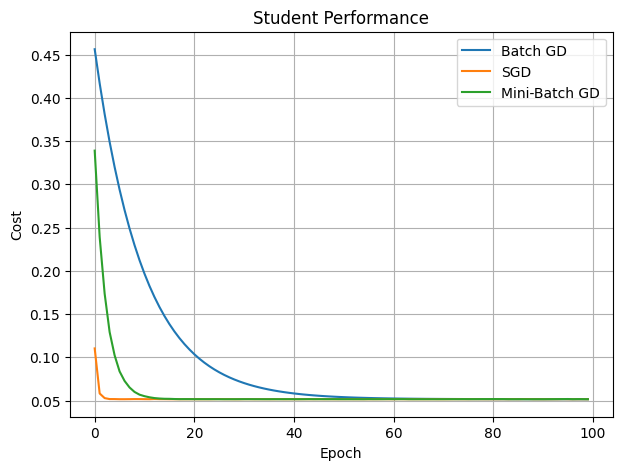


Dataset: Advertising
Batch GD Theta: [[-2.86400533e-16]
 [ 9.36231334e-01]]
Batch GD Final Cost: 0.056515020264755085
SGD Theta: [[-3.57609738e-04]
 [ 9.41433985e-01]]
SGD Final Cost: 0.05649960802518078
Mini-Batch GD Theta: [[0.0071915 ]
 [0.94640555]]
Mini-Batch GD Final Cost: 0.0565359050331985


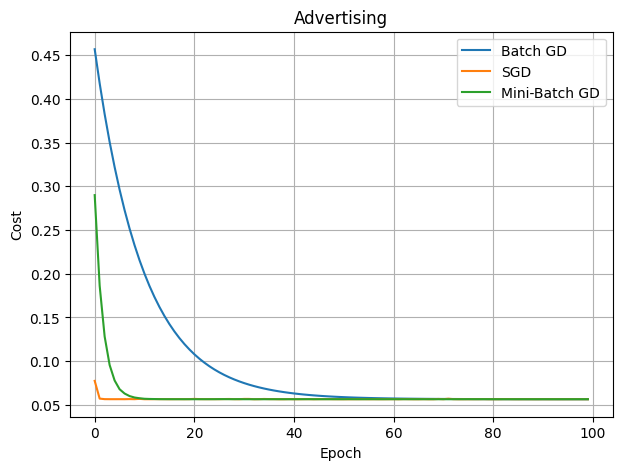


Dataset: Salary
Batch GD Theta: [[4.23596343e-16]
 [9.78202716e-01]]
Batch GD Final Cost: 0.015860742811054176
SGD Theta: [[-0.00600274]
 [ 0.98936449]]
SGD Final Cost: 0.015876023683217708
Mini-Batch GD Theta: [[6.94410068e-04]
 [9.82703631e-01]]
Mini-Batch GD Final Cost: 0.01584489083363645


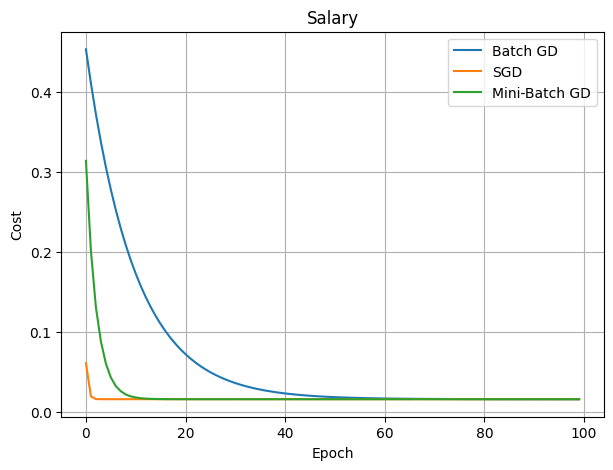


Final Cost Comparison
               Dataset  Batch GD       SGD  Mini-Batch GD
0             Diabetes  0.328044  0.329110       0.328150
1             Linnerud  0.424072  0.424150       0.424104
2  Student Performance  0.051501  0.051495       0.051528
3          Advertising  0.056515  0.056500       0.056536
4               Salary  0.015861  0.015876       0.015845


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes, load_linnerud

np.random.seed(42)






def standardize(X):
    return (X - np.mean(X, axis=0)) / np.std(X, axis=0)

def cost_function(X, y, theta):
    m = len(y)
    prediction = X @ theta
    error = prediction - y
    return np.sum(error ** 2) / (2 * m)

def batch_gradient_descent(X, y, lr=0.01, epochs=100):
    m, n = X.shape
    theta = np.zeros((n, 1))
    costs = []

    for i in range(epochs):
        prediction = X @ theta
        error = prediction - y
        gradient = (X.T @ error) / m
        theta = theta - lr * gradient
        costs.append(cost_function(X, y, theta))

    return theta, costs

def stochastic_gradient_descent(X, y, lr=0.01, epochs=100):
    m, n = X.shape
    theta = np.zeros((n, 1))
    costs = []

    for epoch in range(epochs):
        index = np.random.permutation(m)

        for i in index:
            xi = X[i:i+1]
            yi = y[i:i+1]

            prediction = xi @ theta
            error = prediction - yi
            gradient = xi.T @ error
            theta = theta - lr * gradient

        costs.append(cost_function(X, y, theta))

    return theta, costs

def mini_batch_gradient_descent(X, y, lr=0.01, epochs=100, batch_size=16):
    m, n = X.shape
    theta = np.zeros((n, 1))
    costs = []

    for epoch in range(epochs):
        index = np.random.permutation(m)
        X1 = X[index]
        y1 = y[index]

        for i in range(0, m, batch_size):
            X_batch = X1[i:i+batch_size]
            y_batch = y1[i:i+batch_size]

            prediction = X_batch @ theta
            error = prediction - y_batch
            gradient = (X_batch.T @ error) / len(X_batch)
            theta = theta - lr * gradient

        costs.append(cost_function(X, y, theta))

    return theta, costs


diabetes = load_diabetes()
X1 = diabetes.data[:, 2:3]
y1 = diabetes.target.reshape(-1, 1)

linnerud = load_linnerud()
X2 = linnerud.data[:, 0:1]
y2 = linnerud.target[:, 0].reshape(-1, 1)

hours = np.linspace(1, 10, 100).reshape(-1, 1)
scores = 45 + 5 * hours + np.random.normal(0, 5, (100, 1))
X3 = hours
y3 = scores

advertising = np.linspace(10, 200, 150).reshape(-1, 1)
sales = 20 + 0.4 * advertising + np.random.normal(0, 8, (150, 1))
X4 = advertising
y4 = sales

experience = np.linspace(0, 15, 120).reshape(-1, 1)
salary = 25000 + 4500 * experience + np.random.normal(0, 4000, (120, 1))
X5 = experience
y5 = salary


datasets = [
    ("Diabetes", X1, y1),
    ("Linnerud", X2, y2),
    ("Student Performance", X3, y3),
    ("Advertising", X4, y4),
    ("Salary", X5, y5)
]

results = []

for name, X, y in datasets:
    X = standardize(X)
    y = standardize(y)

    X = np.c_[np.ones((X.shape[0], 1)), X]

    theta_batch, cost_batch = batch_gradient_descent(X, y, 0.05, 100)
    theta_sgd, cost_sgd = stochastic_gradient_descent(X, y, 0.01, 100)
    theta_mini, cost_mini = mini_batch_gradient_descent(X, y, 0.03, 100, 16)

    print("\nDataset:", name)
    print("Batch GD Theta:", theta_batch)
    print("Batch GD Final Cost:", cost_batch[-1])
    print("SGD Theta:", theta_sgd)
    print("SGD Final Cost:", cost_sgd[-1])
    print("Mini-Batch GD Theta:", theta_mini)
    print("Mini-Batch GD Final Cost:", cost_mini[-1])

    results.append([name, cost_batch[-1], cost_sgd[-1], cost_mini[-1]])

    plt.figure(figsize=(7, 5))
    plt.plot(cost_batch, label="Batch GD")
    plt.plot(cost_sgd, label="SGD")
    plt.plot(cost_mini, label="Mini-Batch GD")
    plt.xlabel("Epoch")
    plt.ylabel("Cost")
    plt.title(name)
    plt.legend()
    plt.grid()
    plt.show()


result_table = pd.DataFrame(results, columns=["Dataset", "Batch GD", "SGD", "Mini-Batch GD"])

print("\nFinal Cost Comparison")
print(result_table)


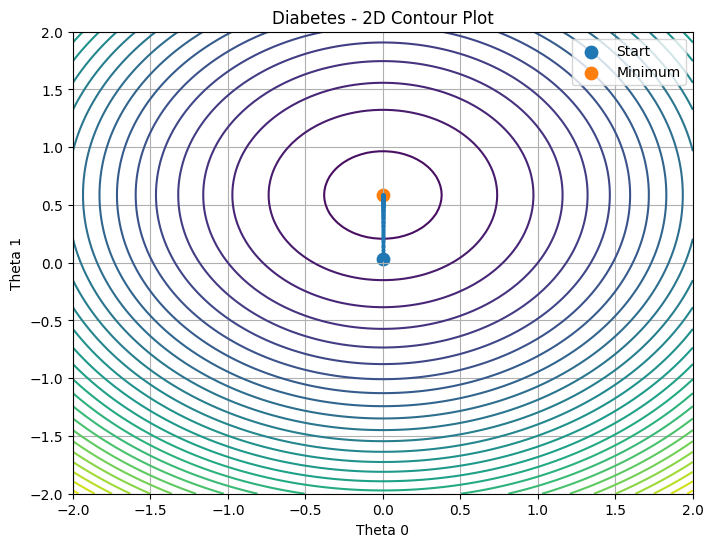

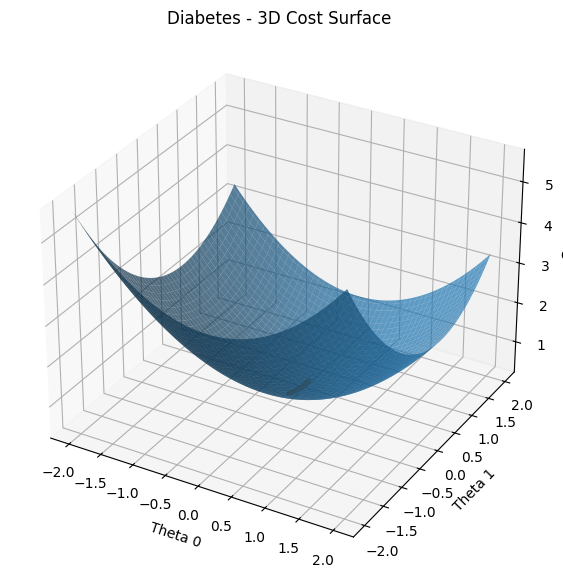

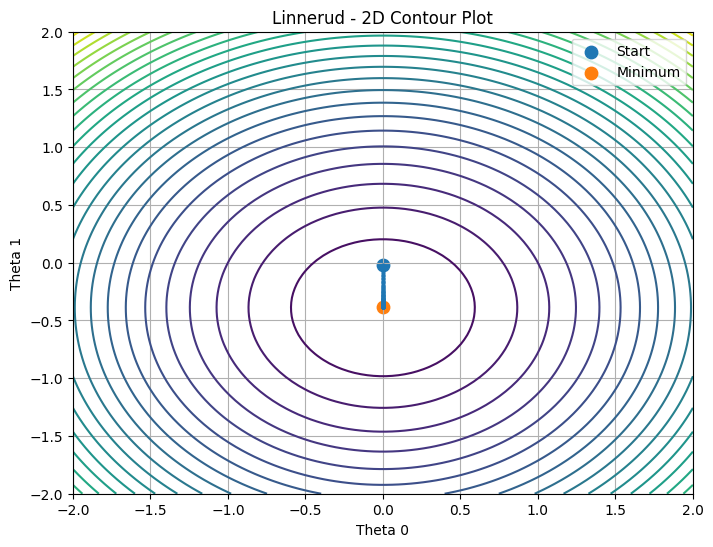

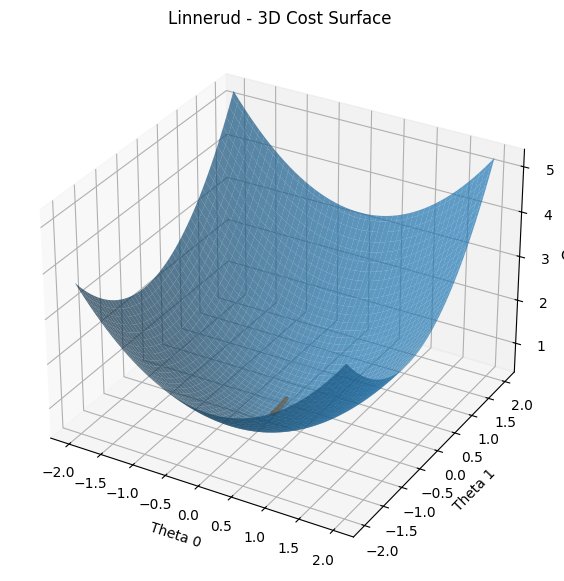

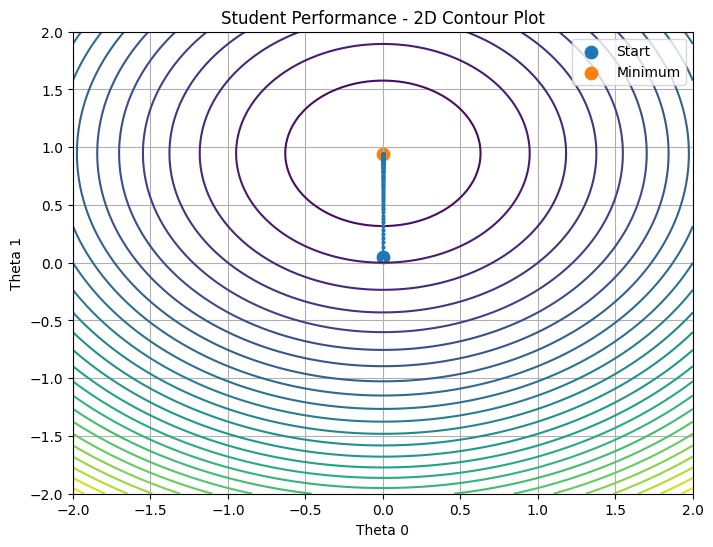

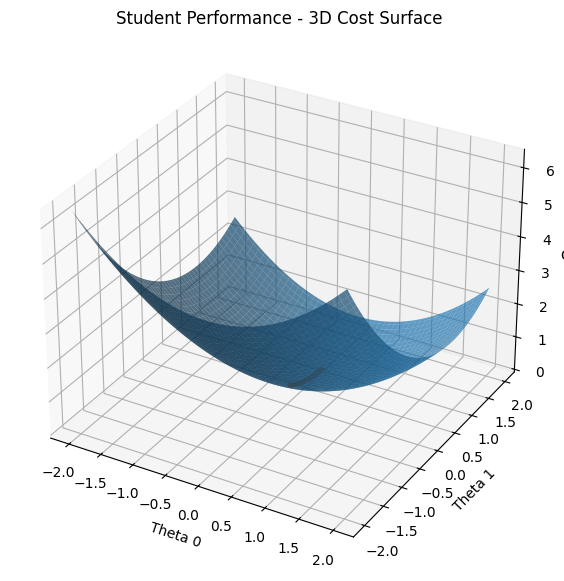

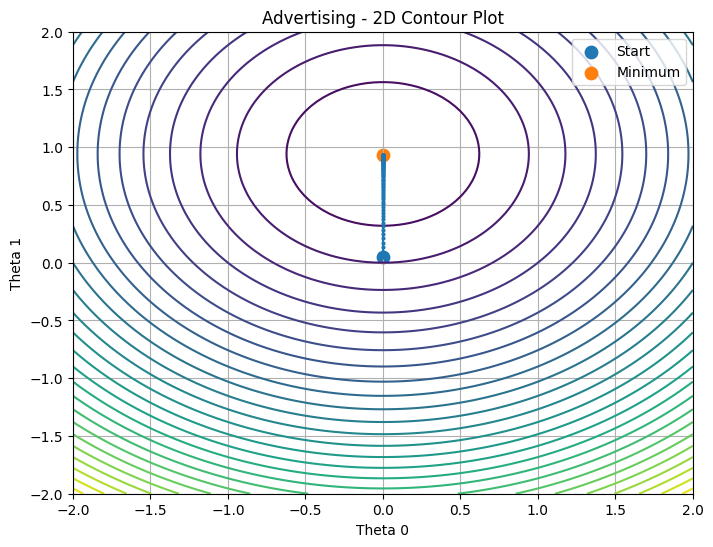

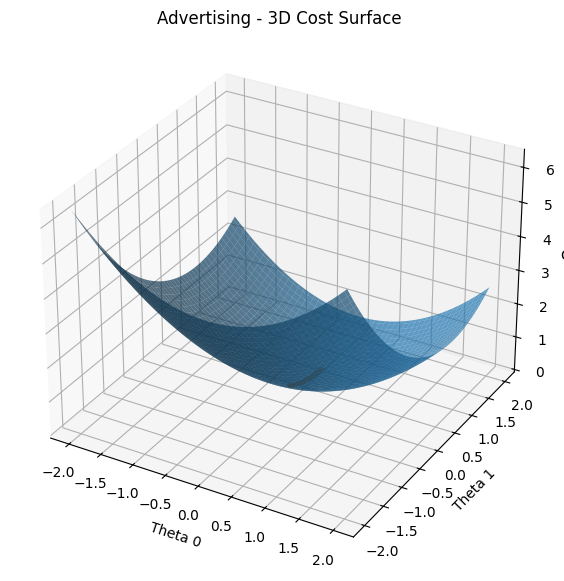

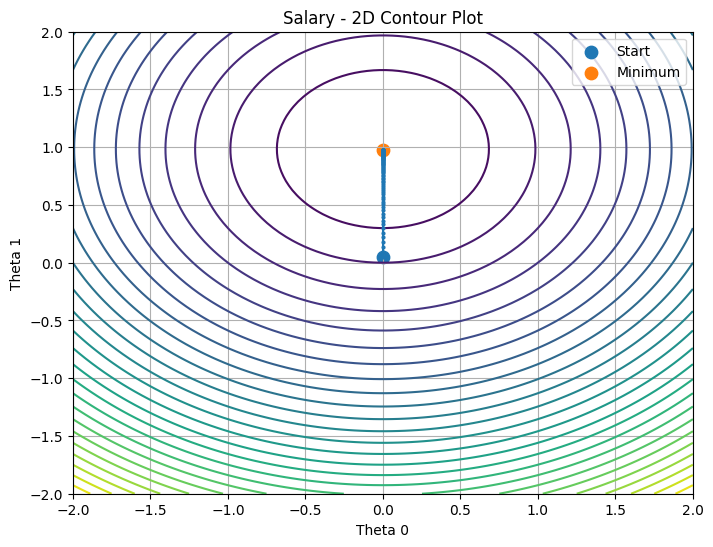

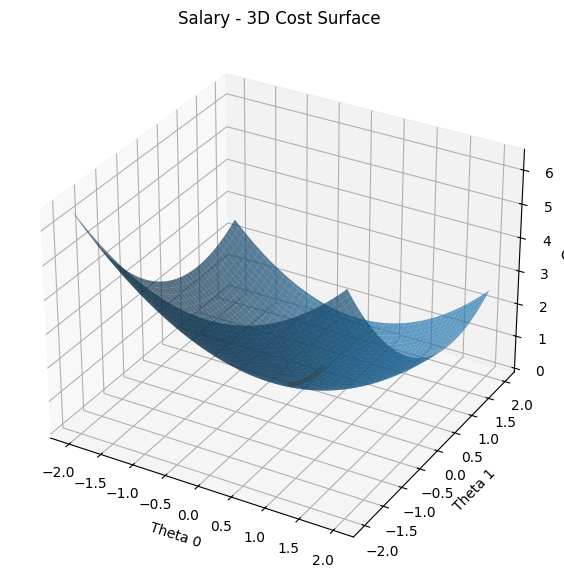

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes, load_linnerud

np.random.seed(42)

def standardize(X):
    return (X - np.mean(X, axis=0)) / np.std(X, axis=0)

def cost_function(X, y, theta):
    m = len(y)
    prediction = X @ theta
    error = prediction - y
    return np.sum(error ** 2) / (2 * m)

def batch_gradient_descent(X, y, lr=0.05, epochs=100):
    m, n = X.shape
    theta = np.zeros((n, 1))
    costs = []
    theta_history = []

    for i in range(epochs):
        prediction = X @ theta
        error = prediction - y
        gradient = (X.T @ error) / m
        theta = theta - lr * gradient

        costs.append(cost_function(X, y, theta))
        theta_history.append(theta.copy())

    return theta, costs, theta_history


diabetes = load_diabetes()
X1 = diabetes.data[:, 2:3]
y1 = diabetes.target.reshape(-1, 1)

linnerud = load_linnerud()
X2 = linnerud.data[:, 0:1]
y2 = linnerud.target[:, 0].reshape(-1, 1)

hours = np.linspace(1, 10, 100).reshape(-1, 1)
scores = 45 + 5 * hours + np.random.normal(0, 5, (100, 1))
X3 = hours
y3 = scores

advertising = np.linspace(10, 200, 150).reshape(-1, 1)
sales = 20 + 0.4 * advertising + np.random.normal(0, 8, (150, 1))
X4 = advertising
y4 = sales

experience = np.linspace(0, 15, 120).reshape(-1, 1)
salary = 25000 + 4500 * experience + np.random.normal(0, 4000, (120, 1))
X5 = experience
y5 = salary


datasets = [
    ("Diabetes", X1, y1),
    ("Linnerud", X2, y2),
    ("Student Performance", X3, y3),
    ("Advertising", X4, y4),
    ("Salary", X5, y5)
]


for name, X, y in datasets:
    X = standardize(X)
    y = standardize(y)
    X = np.c_[np.ones((X.shape[0], 1)), X]

    theta, costs, theta_history = batch_gradient_descent(X, y, 0.05, 100)

    path = np.array([t.flatten() for t in theta_history])

    theta0 = np.linspace(-2, 2, 100)
    theta1 = np.linspace(-2, 2, 100)

    T0, T1 = np.meshgrid(theta0, theta1)

    J = np.zeros(T0.shape)

    for i in range(len(theta0)):
        for j in range(len(theta1)):
            t = np.array([[theta0[i]], [theta1[j]]])
            J[j, i] = cost_function(X, y, t)

    plt.figure(figsize=(8, 6))
    plt.contour(T0, T1, J, levels=30)
    plt.plot(path[:, 0], path[:, 1], "o-", markersize=2)
    plt.scatter(path[0, 0], path[0, 1], s=80, label="Start")
    plt.scatter(path[-1, 0], path[-1, 1], s=80, label="Minimum")
    plt.xlabel("Theta 0")
    plt.ylabel("Theta 1")
    plt.title(name + " - 2D Contour Plot")
    plt.legend()
    plt.grid()
    plt.show()

    fig = plt.figure(figsize=(9, 7))
    ax = fig.add_subplot(111, projection="3d")

    ax.plot_surface(T0, T1, J, alpha=0.7)

    path_cost = []

    for t in path:
        t = t.reshape(-1, 1)
        path_cost.append(cost_function(X, y, t))

    ax.plot(path[:, 0], path[:, 1], path_cost, "o-", markersize=2)

    ax.set_xlabel("Theta 0")
    ax.set_ylabel("Theta 1")
    ax.set_zlabel("Cost")
    ax.set_title(name + " - 3D Cost Surface")

    plt.show()